# Entropy Calculation on Simulated Data

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import entropy

## 1. Shannon Entropy

$$
H(X)=-\sum_{i=1}^{n}p_i\log(p_i)
$$

where $p_i$ is the probability of the $i$-th outcome (here, the $i$-th histogram bin). Shannon entropy measures how spread out / uncertain the **value distribution** is, ignoring temporal order.

### 1.1 Generate simulated data

In [8]:
# Set random seed for reproducibility
rng = np.random.default_rng(42)

# Parameters
mean = 100
n = 1000

# Simulate normal distributions
data_A = rng.normal(loc=mean, scale=5, size=n)
data_B = rng.normal(loc=mean, scale=10, size=n)
data_C = rng.normal(loc=mean, scale=20, size=n)

### 1.2 Visualize the data

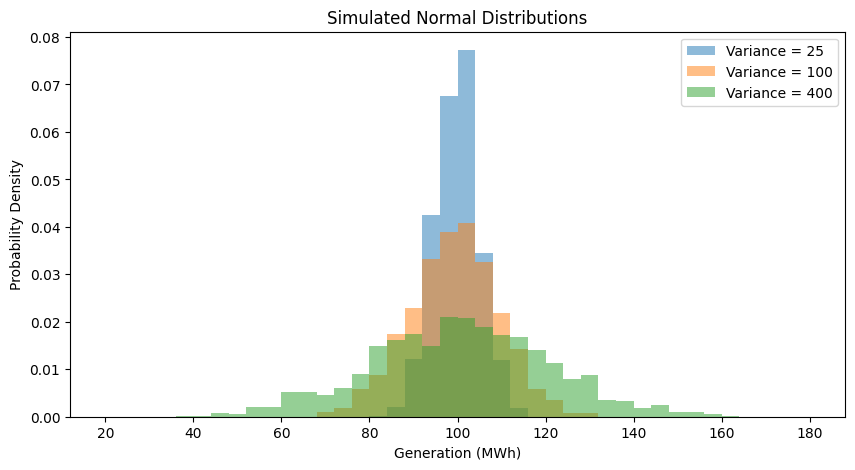

In [9]:
plt.figure(figsize=(10, 5))

bins = np.linspace(20, 180, 41)

plt.hist(data_A, bins=bins, alpha=0.5,
         label="Variance = 25", density=True)
plt.hist(data_B, bins=bins, alpha=0.5,
         label="Variance = 100", density=True)
plt.hist(data_C, bins=bins, alpha=0.5,
         label="Variance = 400", density=True)

plt.xlabel("Generation (MWh)")
plt.ylabel("Probability Density")
plt.title("Simulated Normal Distributions")
plt.legend()
plt.show()

### 1.3 Calculate Shannon Entropy

In [10]:
# Convert data into histogram counts
counts, edges = np.histogram(data_A, bins=bins)
# Convert counts into probabilities
probabilities = counts / counts.sum()
# Calculate Shannon Entropy
H_A = entropy(probabilities, base=2)

print(H_A)

2.4017386968064507


### 1.4 Compare and interpret

In [11]:
datasets = {
    "Variance = 25": data_A,
    "Variance = 100": data_B,
    "Variance = 400": data_C
}

results = []

for name, data in datasets.items():
    counts, _ = np.histogram(data, bins=bins)
    probabilities = counts / counts.sum()
    H = entropy(probabilities, base=2)

    results.append({
        "Scenario": name,
        "Shannon Entropy": H
    })

results_df = pd.DataFrame(results)

print(results_df)

         Scenario  Shannon Entropy
0   Variance = 25         2.401739
1  Variance = 100         3.379857
2  Variance = 400         4.373015


Finding: 
Higher variance → Higher histogram-based Shannon entropy.

## 2. Sample Entropy

$$
\operatorname{SampEn}(m,r)=-\ln\left(\frac{A}{B}\right)
$$

where $B$ is the number of template matches of length $m$ (within tolerance $r$), and $A$ is the number of those matches that still match when extended to length $m+1$ (using a consistent counting convention and excluding self-matches). Sample entropy measures the **irregularity / unpredictability** of a time series: lower values mean more repeating patterns.

## 3. Permutation Entropy

$$
H_{\mathrm{perm}}=-\sum_{\pi}p(\pi)\log p(\pi)
$$

where $p(\pi)$ is not the probability of a generation value, but the relative frequency of the ordinal pattern $\pi$ (the rank ordering of consecutive values) in the time series. Permutation entropy measures the **complexity of ordinal dynamics**: how diverse the up/down patterns are.

## 4. Kolmogorov Entropy